# Phase 4: evaluate (faster cut)
Answers the plan's five questions from the frozen and graded Phase 3 outputs; nothing is re-estimated. Questions 1, 2 and 5 in full (paired comparisons with bootstrap intervals, the maturity chart, the loss ratio test); questions 3 and 4 as short tables. Then the error drivers: ceded swing as a confounder, and the direction of survivorship bias.

Inputs: `results/graded_lines.csv` and `results/graded_ay.csv` from `notebooks/05_phase3_grade.ipynb` (rebuilt by it if missing). Head-to-head comparisons use the D4 common sample (PPA 109, WC 59 lines). "Headline" = CL and BF on volume-weighted all-years factors (D3).

Signs: error = estimate − actual. Positive = over-reserved.

Findings summary at the end. Reviewed 2026-11-09; fixes R1–R5 from the Phase 4 doc applied 2026-11-10 (reporting only: no estimate changed).

In [1]:
# Setup
import sys; sys.path.insert(0, "..")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
R = Path("../results"); FIG = Path("../docs/figures"); FIG.mkdir(parents=True, exist_ok=True)
assert (R / "graded_lines.csv").exists(), "run notebooks/05_phase3_grade.ipynb first"
lines = pd.read_csv(R / "graded_lines.csv")
ay = pd.read_csv(R / "graded_ay.csv")
est = pd.read_csv(R / "estimates.csv", usecols=["lob", "GRCODE", "basis", "AccidentYear", "ep", "latest", "method", "average", "elr"])

HEAD = "volume_all"
def combo(df):
    return np.select([df.method == "cl", df.method == "ec"],
                     ["CL", "EC " + df.elr.fillna("")], "BF " + df.elr.fillna(""))
for d in (lines, ay):
    d["combo"] = combo(d)
    d["headline"] = (d.method == "ec") | (d.average == HEAD)
common = lines.loc[lines.in_common, ["lob", "GRCODE"]].drop_duplicates()
ay = ay.merge(common.assign(in_common=True), on=["lob", "GRCODE"], how="left").fillna({"in_common": False})
ORDER = ["CL", "BF company", "BF industry", "EC company", "EC industry"]
pct = lambda x: f"{x:+.1%}"
rng = np.random.default_rng(20261108)  # bootstrap seed, fixed before any interval was computed
print("common-sample lines:", common.groupby("lob").size().to_dict())

common-sample lines: {'PPA': 109, 'WC': 59}


## Question 1: most accurate method on total reserves, by line
Paired comparison: for each line, |error| of chain ladder minus |error| of the other method, both as % of reserve on the line total (AYs 1999–2007). Negative = chain ladder closer on that line. Pairing removes company-to-company noise: a line that is hard to reserve is hard for both methods, and the difference cancels it. Each comparison is run within one line of business × basis (4 groups). The interval is a 95% bootstrap interval for the median difference (10,000 resamples of lines; 2,000 left the edge of the WC paid interval moving across 0 between seeds). An interval that contains 0 is read as a tie. Lines whose actual unpaid total is ≤ 0 have no % of reserve and are left out of these pairs.

Why expected claims misses by about 100% of reserve: its error ÷ EP = ELR − actual loss ratio, at every age. A reserve is a fraction of EP (small for short-tailed PPA), so an ELR a few points off EP is a large share of the reserve.

In [2]:
# Q1: paired |error| differences vs chain ladder, headline combinations, common sample
def boot_median(x, reps=10_000):
    x = np.asarray(x); idx = rng.integers(0, len(x), (reps, len(x)))
    return np.percentile(np.median(x[idx], axis=1), [2.5, 97.5])

h = lines[lines.in_common & lines.headline]
w = h.pivot_table(index=["lob", "basis", "GRCODE"], columns="combo", values="pct_reserve")
rows = []
for (lob, basis), g in w.groupby(level=[0, 1]):
    for other in ORDER[1:]:
        pair = g[["CL", other]].dropna()
        d = pair.CL.abs() - pair[other].abs()
        lo, hi = boot_median(d)
        rows.append({"lob": lob, "basis": basis, "vs": other, "n": len(d),
                     "med_abs_CL": pair.CL.abs().median(), "med_abs_other": pair[other].abs().median(),
                     "med_diff": d.median(), "ci_lo": lo, "ci_hi": hi,
                     "CL_closer": (d < 0).mean()})
q1 = pd.DataFrame(rows)
q1.to_csv("../docs/phase4_q1_paired.csv", index=False, float_format="%.6f")
fmt = {c: "{:.1%}".format for c in ["med_abs_CL", "med_abs_other", "CL_closer"]}
fmt |= {c: "{:+.1%}".format for c in ["med_diff", "ci_lo", "ci_hi"]}
print(q1.to_string(index=False, formatters=fmt))

lob    basis          vs   n med_abs_CL med_abs_other med_diff   ci_lo  ci_hi CL_closer
PPA     paid  BF company 101      18.8%         22.8%    -1.0%   -5.7%  +2.9%     52.5%
PPA     paid BF industry 101      18.8%         22.3%    -1.1%   -5.4%  +2.2%     54.5%
PPA     paid  EC company 101      18.8%        103.4%   -75.5% -113.6% -47.6%     87.1%
PPA     paid EC industry 101      18.8%         95.7%   -71.6%  -98.1% -50.7%     90.1%
PPA reported  BF company 101      14.7%         12.8%    +0.2%   -0.5%  +0.9%     46.5%
PPA reported BF industry 101      14.7%         15.9%    +0.1%   -1.1%  +0.8%     49.5%
PPA reported  EC company 101      14.7%        102.9%   -89.0% -105.7% -54.5%     86.1%
PPA reported EC industry 101      14.7%         94.1%   -78.4% -101.4% -63.8%     92.1%
 WC     paid  BF company  56      28.5%         41.9%    -8.9%  -17.1%  +0.0%     62.5%
 WC     paid BF industry  56      28.5%         32.5%    -1.7%  -19.2%  +6.4%     51.8%
 WC     paid  EC company  56    

## Question 2: error vs maturity
AY-level absolute error as % of EP (the scale Phase 2 chose for AY rows, since % of reserve explodes on mature AYs), median across company-AYs at each age at 12/31/2007, common sample, headline combinations. Age 12 = AY 2007 (least developed), 108 = AY 1999. The chart shows chain ladder and BF; expected claims is in the table (an order of magnitude worse at every age). n is the number of company-AYs at each age: it falls at young ages because incomplete lines lack their latest AYs.

In [3]:
# Q2: median |error| (% of EP) by maturity, method, lob, basis
a = ay[ay.in_common & ay.headline & ay.error.notna()]
q2 = (a.assign(abs_ep=a.pct_ep.abs())
        .groupby(["lob", "basis", "combo", "age"]).abs_ep.agg(["median", "size"]).reset_index())
q2.to_csv("../docs/phase4_q2_maturity.csv", index=False, float_format="%.6f")
tab = q2.pivot_table(index=["lob", "basis", "age"], columns="combo", values="median")[ORDER]
n_age = q2.drop_duplicates(["lob", "basis", "age"]).set_index(["lob", "basis", "age"])["size"].rename("n")
print(tab.join(n_age).to_string(formatters={c: "{:.1%}".format for c in ORDER}))

                   CL BF company BF industry EC company EC industry    n
lob basis    age                                                        
PPA paid     12  5.7%       4.9%        5.6%      10.8%        8.1%   95
             24  2.5%       3.0%        4.5%      10.6%       11.2%   97
             36  1.9%       2.0%        2.6%       8.4%       10.4%   97
             48  1.0%       1.1%        1.2%      11.0%       10.0%  101
             60  0.9%       0.9%        1.0%       9.7%        8.0%  101
             72  0.4%       0.3%        0.5%       9.9%       10.6%  102
             84  0.2%       0.2%        0.3%      10.6%       12.3%  106
             96  0.1%       0.1%        0.1%      10.9%       12.4%  107
             108 0.0%       0.0%        0.0%       7.7%        9.2%  109
    reported 12  4.1%       4.4%        5.7%      10.8%        8.1%   95
             24  2.4%       2.6%        3.0%      10.4%       11.1%   97
             36  1.6%       1.7%        1.8%       

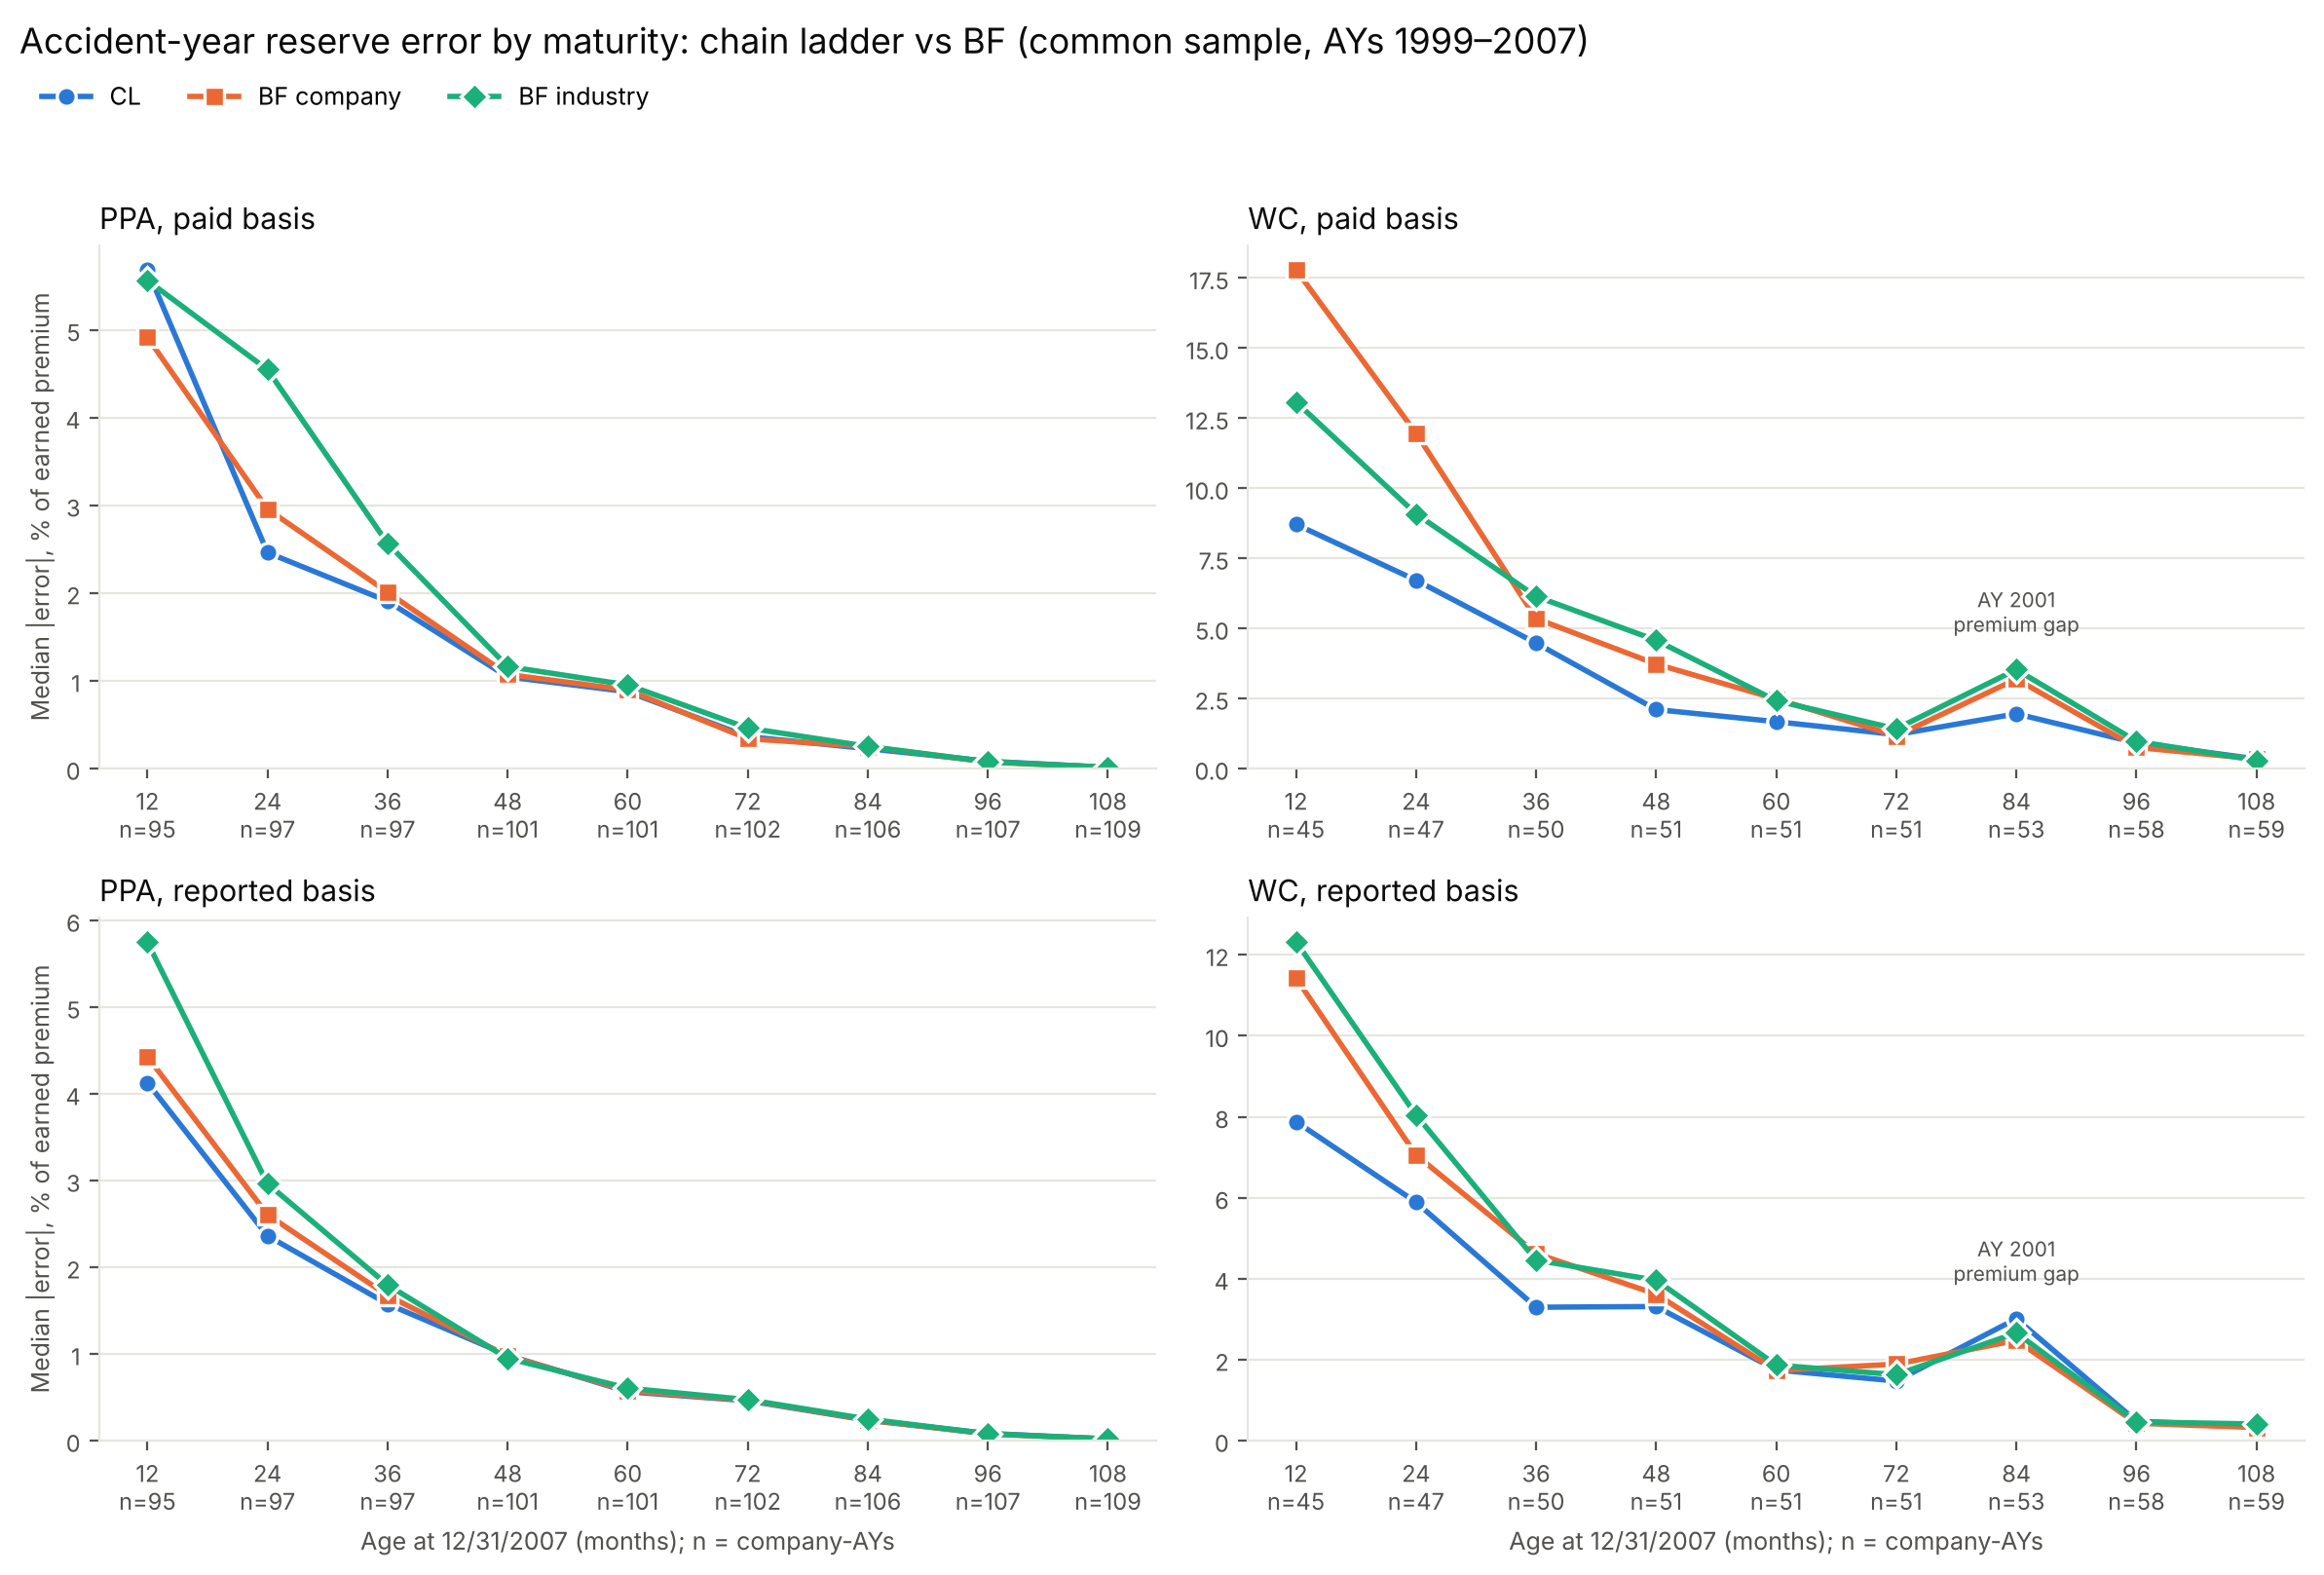

In [4]:
# Q2 chart: CL vs BF by maturity, one panel per line of business x basis. Expected claims is an
# order of magnitude worse at every age (table above), so it is left out to keep CL vs BF readable.
CHART = ["CL", "BF company", "BF industry"]
COLORS = dict(zip(CHART, ["#2a78d6", "#eb6834", "#1baf7a"]))  # validated slots 1-3, fixed order
MARKERS = dict(zip(CHART, ["o", "s", "D"]))  # secondary encoding: aqua is < 3:1 on white
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"

fig, axes = plt.subplots(2, 2, figsize=(12, 8.2), sharex="col")
for i, lob in enumerate(["PPA", "WC"]):
    for j, basis in enumerate(["paid", "reported"]):
        ax = axes[j, i]
        sub = q2[(q2.lob == lob) & (q2.basis == basis)]
        for c in CHART:
            s = sub[sub.combo == c].sort_values("age")
            ax.plot(s.age, s["median"] * 100, color=COLORS[c], lw=2, marker=MARKERS[c], ms=7,
                    markeredgecolor="white", markeredgewidth=1.2, label=c)
        n = sub.drop_duplicates("age").sort_values("age")
        ax.set_xticks(n.age)
        ax.set_xticklabels([f"{a}\nn={k}" for a, k in zip(n.age, n["size"])], fontsize=8)
        if lob == "WC":
            y84 = sub[(sub.age == 84) & sub.combo.isin(CHART)]["median"].max() * 100
            ax.annotate("AY 2001\npremium gap", (84, y84), xytext=(0, 14), textcoords="offset points",
                        ha="center", fontsize=7.5, color=MUTED)
        ax.set_title(f"{lob}, {basis} basis", loc="left", fontsize=11, color=INK)
        ax.set_ylim(bottom=0)
        ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
        for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
        for sp in ["left", "bottom"]: ax.spines[sp].set_color(GRID)
        ax.tick_params(colors=MUTED, labelsize=8.5)
        if i == 0: ax.set_ylabel("Median |error|, % of earned premium", color=MUTED, fontsize=9)
        if j == 1: ax.set_xlabel("Age at 12/31/2007 (months); n = company-AYs", color=MUTED, fontsize=9)
        ax.tick_params(axis="x", labelbottom=True)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.suptitle("Accident-year reserve error by maturity: chain ladder vs BF (common sample, AYs 1999–2007)",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.01, 0.955), ncol=3, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(FIG / "q2_error_by_maturity.png", dpi=160, bbox_inches="tight")
plt.show()

### Data check: premium recorded far too low (mostly WC AY 2001)
The age-84 spike for WC (AY 2001) is a data issue, found here after grading. In many WC lines, AY 2001's net earned premium is a few percent of the line's other years while its losses are normal. Phase 1 rule 2 dropped lines where premium was exactly 0 (the same AY 2001 gap); these have small positive premium, so they passed. Both symptoms are in known data (premium and reported losses at 12/31/2007), so a rule could have caught them before the freeze.

Flag (known data only): a company-AY whose EP is under 25% of the line's median EP in its other AYs **and** whose known reported loss ratio (reported to date ÷ EP) is over 4× the median of the line's other AYs. Low EP alone also catches books that grew or shrank (their loss ratios are normal), so the loss ratio test separates a recording error from a small year. The multiples among low-EP AYs have a gap between about 3.3× and 5.3× (printed below), so any cutoff in that gap flags the same AYs.

Effect: chain ladder doesn't use premium, so only its % of EP denominator is distorted; expected claims and BF use ELR × EP, so they understate these AYs. The pre-specified results stand as frozen; below is a sensitivity with the flagged company-AYs removed.

In [5]:
# Flag company-AYs with premium recorded far too low: known data only (EP, reported to date at 12/31/2007)
k = est[(est.method == "cl") & (est.average == HEAD)].copy()
k = k[k.basis == "reported"][["lob", "GRCODE", "AccidentYear", "ep", "latest"]]
k["lr"] = k.latest / k.ep
rows = []
for (lob, g), d in k.groupby(["lob", "GRCODE"]):
    d = d.set_index("AccidentYear")
    for y in d.index:
        o = d.drop(y)
        rows.append({"lob": lob, "GRCODE": g, "AccidentYear": y, "rel_ep": d.ep[y] / o.ep.median(),
                     "rel_lr": d.lr[y] / o.lr.median() if o.lr.median() > 0 else np.nan})
flags = pd.DataFrame(rows)
EP_CUT, LR_CUT = 0.25, 4.0
low = flags[flags.rel_ep < EP_CUT]
flags["bad_premium"] = (flags.rel_ep < EP_CUT) & (flags.rel_lr > LR_CUT)
print(f"Low-EP company-AYs (EP < {EP_CUT:.0%} of line median): {len(low)}")
print(f"  largest loss ratio multiple at or below {LR_CUT}x: {low.rel_lr[low.rel_lr <= LR_CUT].max():.2f}x; "
      f"smallest above: {low.rel_lr[low.rel_lr > LR_CUT].min():.2f}x  (the gap)")
print("\nFlagged company-AYs (low EP and loss ratio > 4x the line's other AYs):")
print(flags[flags.bad_premium].groupby(["lob", "AccidentYear"]).size().unstack(fill_value=0))
n01 = flags[(flags.lob == "WC") & (flags.AccidentYear == 2001)]
print(f"WC lines with AY 2001: {len(n01)}; flagged: {n01.bad_premium.sum()}")
ex = k[(k.lob == "WC") & (k.GRCODE == 7080) & k.AccidentYear.between(2000, 2002)].set_index("AccidentYear")
print("\nExample, WC GRCODE 7080 ($000):"); print(ex[["ep", "latest", "lr"]].rename(columns={"latest": "reported_to_date"}).round(2))

aa = ay[ay.in_common & ay.headline].merge(flags[["lob", "GRCODE", "AccidentYear", "bad_premium"]],
                                         on=["lob", "GRCODE", "AccidentYear"], how="left").fillna({"bad_premium": False})
def line_med_abs(df):
    t = df.groupby(["lob", "basis", "combo", "GRCODE"]).agg(err=("error", "sum"), au=("actual_unpaid", "sum"))
    t = t[t.au > 0]
    return (t.err / t.au).abs().groupby(["lob", "basis", "combo"]).median()
sens = pd.DataFrame({"all AYs (frozen)": line_med_abs(aa), "flagged AYs out": line_med_abs(aa[~aa.bad_premium])})
sens["change (points)"] = (sens["flagged AYs out"] - sens["all AYs (frozen)"]) * 100
print("\nMedian |error|, % of reserve, line totals, headline combinations:")
print(sens.to_string(formatters={"all AYs (frozen)": "{:.1%}".format, "flagged AYs out": "{:.1%}".format,
                                 "change (points)": "{:+.1f}".format}))
sens.to_csv("../docs/phase4_premium_sensitivity.csv", float_format="%.6f")

Low-EP company-AYs (EP < 25% of line median): 74
  largest loss ratio multiple at or below 4.0x: 3.26x; smallest above: 5.31x  (the gap)

Flagged company-AYs (low EP and loss ratio > 4x the line's other AYs):
AccidentYear  1998  2001  2002  2007
lob                                 
PPA              0     0     0     1
WC               1    22     1     0
WC lines with AY 2001: 54; flagged: 22

Example, WC GRCODE 7080 ($000):
                    ep  reported_to_date     lr
AccidentYear                                   
2000          204778.0          170063.0   0.83
2001            2452.0          192429.0  78.48
2002          292842.0          220833.0   0.75

Median |error|, % of reserve, line totals, headline combinations:
                         all AYs (frozen) flagged AYs out change (points)
lob basis    combo                                                       
PPA paid     BF company             22.8%           22.8%            +0.0
             BF industry            22.3% 

Reading the sensitivity: chain ladder and BF move by about 1 point or less. Expected claims gets **worse** on WC without the flagged AYs. On a flagged AY, expected claims = ELR × a tiny EP, a large under-estimate; in a line total that offsets expected claims' over-estimates on the hard-market AYs (question 5). Removing the flagged AY removes the offset. So the frozen results don't flatter chain ladder or BF.

One flagged AY is an AY 1998 (WC GRCODE 10048), which is that line's company ELR input, so its company ELR (149%) is inflated too. Kept as frozen; one line.

## Question 5: BF sensitivity to the expected loss ratio
The plan's hypothesis: an ELR from the soft-market AY 1998 overstates hard-market AYs, biasing BF and expected claims but not chain ladder. Three checks:
1. **Industry loss ratio by AY.** The industry ELR is the AY 1998 premium-weighted loss ratio at 120 months. The same ratio for every later AY (actual, at 120) shows how far each AY ended from the ELR the methods used.
2. **How much of BF's error is the ELR.** BF = Z × CL + (1 − Z) × EC with Z = 1/CDF, so BF error = Z × (CL error) + (1 − Z) × (EC error) exactly. The second term is the ELR's contribution (EC error ÷ EP = ELR − actual loss ratio); the first is development error. Summed over a line's AYs, the split shows which one drives BF's miss.
3. **Company vs industry ELR**, paired on line totals.

In [6]:
# Q5.1: industry actual loss ratio at 120 by AY vs the ELR (= AY 1998 value); flagged premium AYs left out
act = ay.drop_duplicates(["lob", "GRCODE", "basis", "AccidentYear"]).merge(
    flags[["lob", "GRCODE", "AccidentYear", "bad_premium"]], on=["lob", "GRCODE", "AccidentYear"], how="left")
act = act[~act.bad_premium.fillna(False).astype(bool)]
lr = act.groupby(["lob", "basis", "AccidentYear"]).agg(loss=("actual_120", "sum"), ep=("ep", "sum"))
lr["lr"] = lr.loss / lr.ep
ay98 = est[(est.AccidentYear == 1998) & (est.method == "cl") & (est.average == HEAD)]
elr_ind = (ay98.groupby(["lob", "basis"]).latest.sum() / ay98.groupby(["lob", "basis"]).ep.sum()).rename("industry_elr")
q5 = lr.lr.unstack("AccidentYear").join(elr_ind)
print("Industry loss ratio at 120 by AY (AYs 1999-2007 actual, flagged premium AYs left out; industry ELR = AY 1998,")
print("as frozen). Points below the ELR = BF and expected claims over-reserve that AY. WC AY 2001 rests on 32 of 54")
print("lines and dips well below AYs 2000 and 2002; read it with caution.")
print((q5 * 100).round(1).to_string())
q5.to_csv("../docs/phase4_q5_loss_ratios.csv", float_format="%.6f")

Industry loss ratio at 120 by AY (AYs 1999-2007 actual, flagged premium AYs left out; industry ELR = AY 1998,
as frozen). Points below the ELR = BF and expected claims over-reserve that AY. WC AY 2001 rests on 32 of 54
lines and dips well below AYs 2000 and 2002; read it with caution.
              1999  2000  2001  2002  2003  2004  2005  2006  2007  industry_elr
lob basis                                                                       
PPA paid      75.7  81.4  82.1  77.9  68.4  65.3  66.1  66.1  70.3          69.1
    reported  75.9  81.6  82.3  78.1  68.6  65.4  66.2  66.3  70.4          69.2
WC  paid      69.4  68.7  43.8  62.8  54.2  47.8  44.8  46.4  55.2          64.2
    reported  75.1  73.6  53.1  67.7  58.5  52.1  49.0  51.1  59.3          68.2


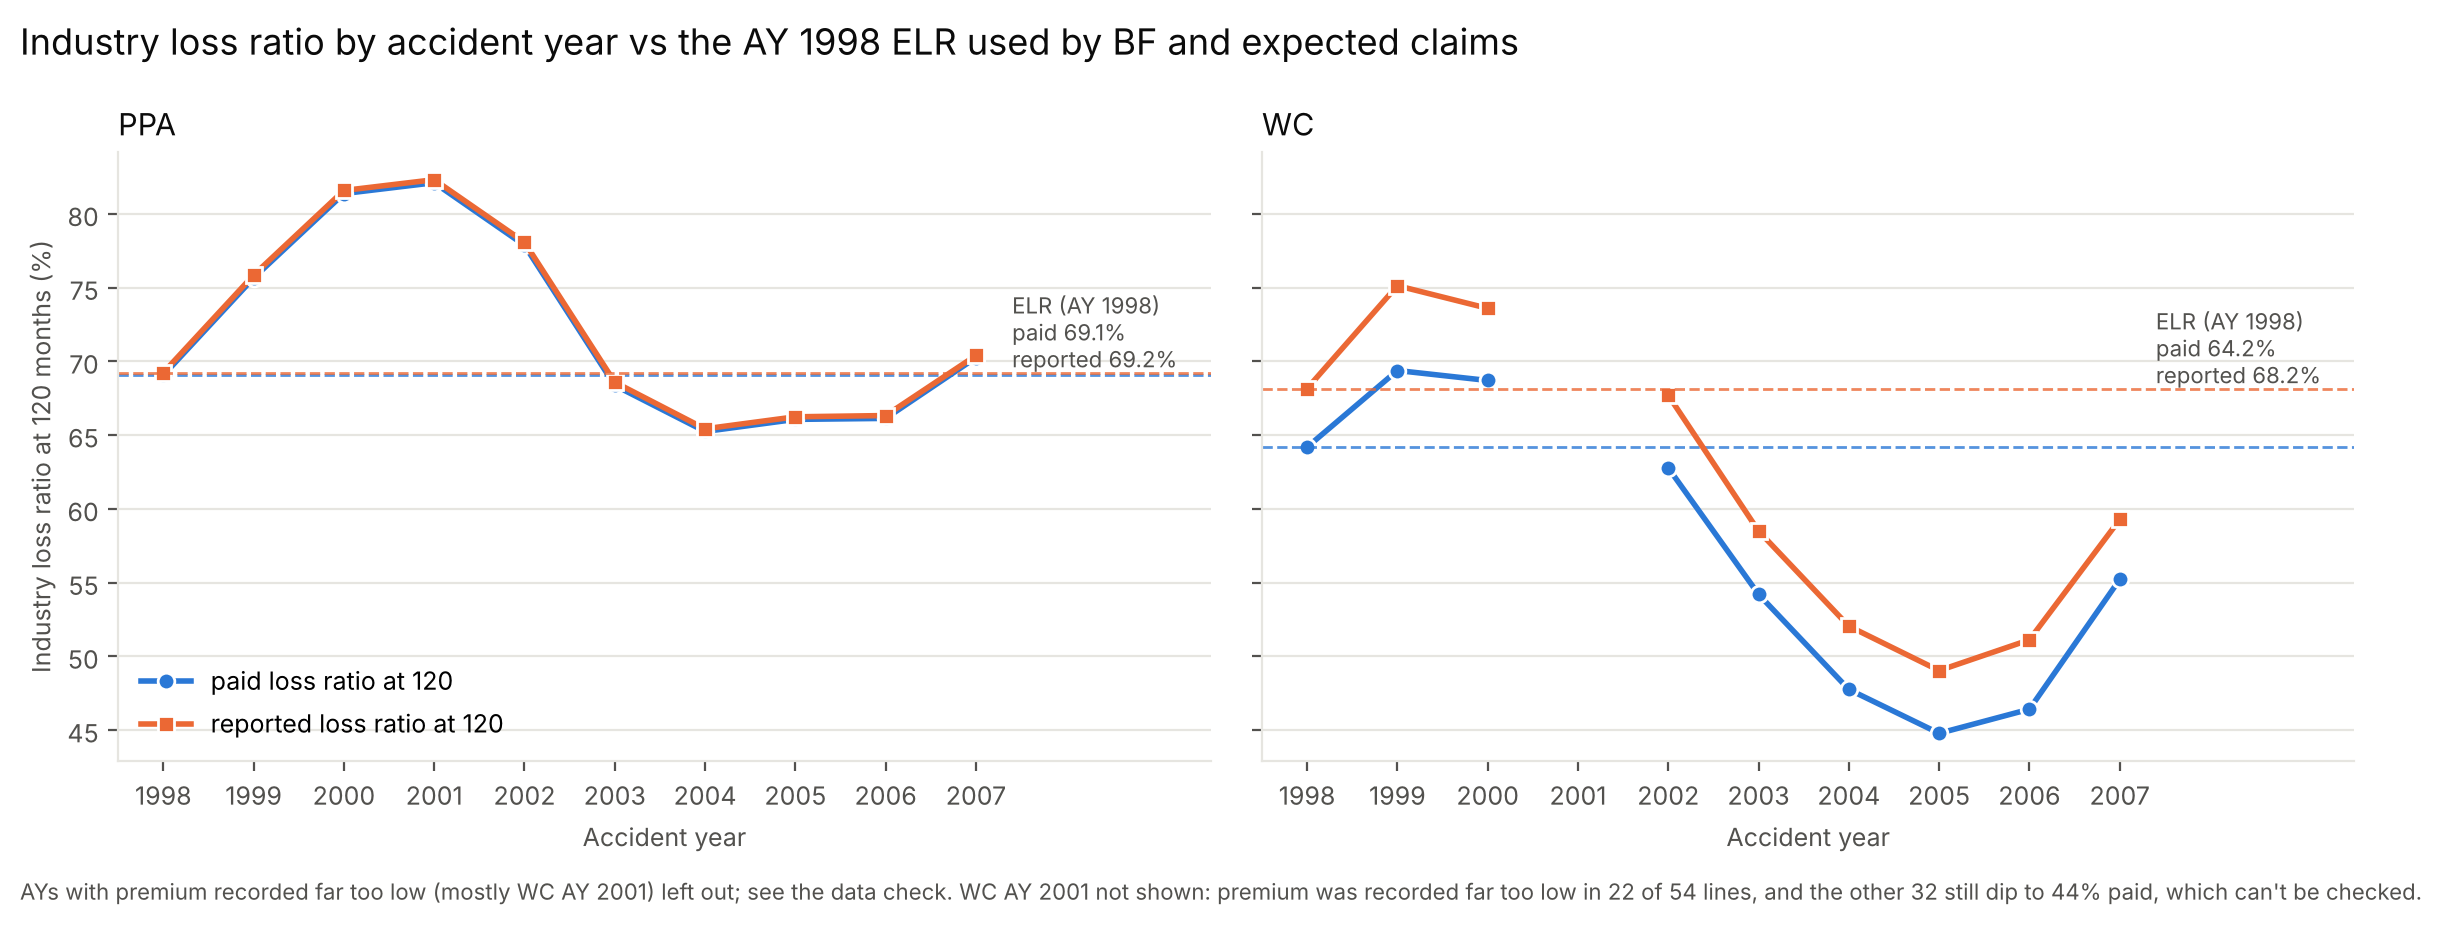

In [7]:
# Q5.1 chart: industry loss ratio by AY (AY 1998 = the industry ELR), ELR as a dashed reference
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
BASIS_C = {"paid": "#2a78d6", "reported": "#eb6834"}
for ax, lob in zip(axes, ["PPA", "WC"]):
    for basis in ["paid", "reported"]:
        e = q5.loc[(lob, basis), "industry_elr"]
        s = pd.concat([pd.Series({1998: e}), lr.loc[(lob, basis)].lr]) * 100
        if lob == "WC":
            s[2001] = np.nan  # not shown: see note under the chart
        ax.plot(s.index, s.values, color=BASIS_C[basis], lw=2, marker="o" if basis == "paid" else "s",
                ms=6, markeredgecolor="white", label=f"{basis} loss ratio at 120")
        ax.axhline(e * 100, color=BASIS_C[basis], lw=1, ls="--", alpha=0.8)
    pe, re_ = q5.loc[(lob, "paid"), "industry_elr"], q5.loc[(lob, "reported"), "industry_elr"]
    ax.annotate(f"ELR (AY 1998)\npaid {pe:.1%}\nreported {re_:.1%}", (2007.4, max(pe, re_) * 100),
                va="bottom", fontsize=8, color=MUTED)
    ax.set_title(lob, loc="left", fontsize=11, color=INK); ax.set_xticks(range(1998, 2008))
    ax.set_xlim(1997.5, 2009.6)
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
    for sp in ["left", "bottom"]: ax.spines[sp].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9); ax.set_xlabel("Accident year", color=MUTED, fontsize=9)
axes[0].set_ylabel("Industry loss ratio at 120 months (%)", color=MUTED, fontsize=9)
axes[0].legend(frameon=False, fontsize=9, loc="lower left")
fig.suptitle("Industry loss ratio by accident year vs the AY 1998 ELR used by BF and expected claims",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.text(0.01, -0.02, "AYs with premium recorded far too low (mostly WC AY 2001) left out; see the data check. WC AY 2001 not shown: premium was recorded far too low in 22 of 54 lines, and the other 32 still dip to 44% paid, which can't be checked.", fontsize=8, color=MUTED)
fig.tight_layout(); fig.savefig(FIG / "q5_loss_ratio_by_ay.png", dpi=160, bbox_inches="tight"); plt.show()

In [8]:
# Q5.2: split BF error into development (Z x CL error) and ELR (1 - Z) x EC error, headline average, common sample
key = ["lob", "GRCODE", "basis", "AccidentYear"]
bf_ = ay[ay.in_common & (ay.method == "bf") & (ay.average == HEAD)]
cl_ = ay[ay.in_common & (ay.method == "cl") & (ay.average == HEAD)][key + ["error"]].rename(columns={"error": "cl_err"})
ec_ = ay[ay.in_common & (ay.method == "ec")][key + ["elr", "error"]].rename(columns={"error": "ec_err"})
b = bf_.merge(cl_, on=key).merge(ec_, on=key + ["elr"])
b["Z"] = 1 / b.cdf
b["from_dev"] = b.Z * b.cl_err
b["from_elr"] = (1 - b.Z) * b.ec_err
gap = (b.error - b.from_dev - b.from_elr).abs().max()
assert gap < 1e-6, gap
print(f"BF error = Z x CL error + (1 - Z) x EC error on all {len(b):,} AY rows (max gap {gap:.1e})")
t = b.groupby(["lob", "basis", "elr", "GRCODE"])[["error", "from_dev", "from_elr", "actual_unpaid"]].sum()
t = t[t.actual_unpaid > 0]
g = t.groupby(["lob", "basis", "elr"])
q5b = pd.DataFrame({
    "n": g.size(),
    "BF_median": g.apply(lambda d: (d.error / d.actual_unpaid).median()),
    "from_dev_median": g.apply(lambda d: (d.from_dev / d.actual_unpaid).median()),
    "from_elr_median": g.apply(lambda d: (d.from_elr / d.actual_unpaid).median()),
    "elr_share_of_abs": g.apply(lambda d: d.from_elr.abs().sum() / (d.from_elr.abs() + d.from_dev.abs()).sum())})
print("\nLine totals, % of reserve. Medians of each part are taken separately, so they don't add to the BF median.")
print(q5b.to_string(formatters={c: "{:+.1%}".format for c in ["BF_median", "from_dev_median", "from_elr_median"]} |
                     {"elr_share_of_abs": "{:.0%}".format}))
print("\nMedian weight on the ELR (1 - Z) by age, paid basis:")
print((1 - b[b.basis == "paid"].groupby(["lob", "age"]).Z.median()).unstack("age").round(2).to_string())

BF error = Z x CL error + (1 - Z) x EC error on all 5,520 AY rows (max gap 3.7e-09)

Line totals, % of reserve. Medians of each part are taken separately, so they don't add to the BF median.
                         n BF_median from_dev_median from_elr_median elr_share_of_abs
lob basis    elr                                                                     
PPA paid     company   101     +7.8%           +4.2%           +1.7%              50%
             industry  101    +14.8%           +4.2%           +7.1%              48%
    reported company   101     +4.5%           +2.4%           +0.4%              18%
             industry  101     +3.9%           +2.4%           +1.0%              18%
WC  paid     company    56     +0.7%           +1.0%           -1.2%              76%
             industry   56    +19.9%           +1.0%          +26.0%              75%
    reported company    58     +2.7%           +4.5%           -0.2%              46%
             industry   58    +11.7

Reading Q5.2: on WC the ELR term is most of BF's error, and with the industry ELR it is nearly all of BF's over-reserving. With a correct ELR the second term would be 0 and BF error would be Z × CL error, smaller than chain ladder's since Z < 1; so BF can only lose to chain ladder through its ELR. The ELR's weight is largest at young ages, which is where BF trails chain ladder on WC (question 2).

In [9]:
# Q5.2b (hindsight, not a usable method): BF if each AY's ELR had equalled its actual loss ratio at 120.
# Then the EC error is 0 and BF error = Z x CL error. Shows how much of BF's loss to chain ladder is the ELR.
hs = b[b.elr == "company"].groupby(["lob", "basis", "GRCODE"])[["cl_err", "from_dev", "actual_unpaid"]].sum()
hs = hs[hs.actual_unpaid > 0]
hs_tab = pd.DataFrame({"CL": (hs.cl_err / hs.actual_unpaid).abs().groupby(["lob", "basis"]).median(),
                       "BF, hindsight ELR": (hs.from_dev / hs.actual_unpaid).abs().groupby(["lob", "basis"]).median()})
print("Median |error|, % of reserve, line totals (hindsight):")
print(hs_tab.to_string(float_format="{:.1%}".format))

Median |error|, % of reserve, line totals (hindsight):
                CL  BF, hindsight ELR
lob basis                            
PPA paid     18.8%              12.7%
    reported 14.7%              12.6%
WC  paid     28.5%              13.7%
    reported 27.8%              18.8%


Reading Q5.2b: with a correct ELR, BF would have been far more accurate than chain ladder on WC (about half its error on the paid basis). So BF's long-tail advantage is real, but only as good as the ELR; this project's ELR is an unadjusted AY 1998 ratio (no rate-change or trend data), which a pricing-informed ELR would improve on. Hindsight only: no one has the actual loss ratio when reserving.

In [10]:
# Q5.3: BF company vs industry ELR, paired on line totals (% of reserve), headline average
rows = []
for (lob, basis), g in w.groupby(level=[0, 1]):
    pair = g[["BF company", "BF industry"]].dropna()
    d = pair["BF company"].abs() - pair["BF industry"].abs()
    lo, hi = boot_median(d)
    rows.append({"lob": lob, "basis": basis, "n": len(d),
                 "med_signed_company": pair["BF company"].median(), "med_signed_industry": pair["BF industry"].median(),
                 "med_abs_company": pair["BF company"].abs().median(), "med_abs_industry": pair["BF industry"].abs().median(),
                 "med_diff": d.median(), "ci_lo": lo, "ci_hi": hi, "company_closer": (d < 0).mean()})
q5c = pd.DataFrame(rows)
print(q5c.to_string(index=False, formatters={c: "{:+.1%}".format for c in
      ["med_signed_company", "med_signed_industry", "med_diff", "ci_lo", "ci_hi"]} |
      {c: "{:.1%}".format for c in ["med_abs_company", "med_abs_industry", "company_closer"]}))

lob    basis   n med_signed_company med_signed_industry med_abs_company med_abs_industry med_diff ci_lo  ci_hi company_closer
PPA     paid 101              +7.8%              +14.8%           22.8%            22.3%    -1.8% -2.9%  +3.4%          52.5%
PPA reported 101              +4.5%               +3.9%           12.8%            15.9%    -0.0% -1.1%  +0.4%          50.5%
 WC     paid  56              +0.7%              +19.9%           41.9%            32.5%   +11.5% +6.3% +20.1%          32.1%
 WC reported  58              +2.7%              +11.7%           26.2%            29.6%    +1.4% -2.8%  +5.8%          46.6%


## Question 3: paid vs reported basis, PPA vs WC (short table)
Headline chain ladder and BF (company ELR), common sample, line totals. Reported-basis unpaid includes case still open at 120, so part of any paid vs reported gap is that built-in difference, not estimation error (`docs/phase3_open_case_by_line.csv`).

In [11]:
q3 = (h[h.combo.isin(["CL", "BF company"])].groupby(["lob", "combo", "basis"]).pct_reserve
        .agg(n="count", median="median", med_abs=lambda s: s.abs().median()).unstack("basis"))
print(q3.to_string(formatters={c: "{:+.1%}".format for c in q3.columns if c[0] == "median"} |
                               {c: "{:.1%}".format for c in q3.columns if c[0] == "med_abs"}))
oc = pd.read_csv("../docs/phase3_open_case_by_line.csv")
print("\nOpen case at 120, median share of actual reported unpaid:",
      oc.groupby("lob").pct_of_reported_unpaid.median().map("{:.1%}".format).to_dict())

                  n          median          med_abs         
basis          paid reported   paid reported    paid reported
lob combo                                                    
PPA BF company  101      101  +7.8%    +4.5%   22.8%    12.8%
    CL          101      101  +6.9%    +3.2%   18.8%    14.7%
WC  BF company   56       58  +0.7%    +2.7%   41.9%    26.2%
    CL           56       58  +4.5%    +5.0%   28.5%    27.8%

Open case at 120, median share of actual reported unpaid: {'PPA': '0.5%', 'WC': '15.1%'}


## Question 4: best averaging method (short table)
Chain ladder under each of the 6 averages, common sample, median |error| as % of reserve on line totals, ranked within each line of business × basis. **In-sample:** the averages are scored on the same data used to rank them, so the winner's edge is likely overstated; only the headline (volume-weighted all years) was picked in advance (D3). An out-of-sample check needs the second era (plan extension).

In [12]:
cl = lines[lines.in_common & (lines.method == "cl")]
q4 = cl.groupby(["lob", "basis", "average"]).pct_reserve.agg(
    med_abs=lambda s: s.abs().median(), median="median", n="count").reset_index()
q4["rank"] = q4.groupby(["lob", "basis"]).med_abs.rank().astype(int)
print(q4.sort_values(["lob", "basis", "rank"]).to_string(index=False,
      formatters={"med_abs": "{:.1%}".format, "median": "{:+.1%}".format}))

lob    basis    average med_abs median   n  rank
PPA     paid   simple_3   15.4%  +3.6% 101     1
PPA     paid   volume_3   16.0%  +3.9% 101     2
PPA     paid   volume_5   16.8%  +4.9% 101     3
PPA     paid   simple_5   17.1%  +6.1% 101     4
PPA     paid volume_all   18.8%  +6.9% 101     5
PPA     paid simple_all   20.4%  +8.1% 101     6
PPA reported   simple_3    8.8%  +0.2% 101     1
PPA reported   volume_3    9.9%  +0.1% 101     2
PPA reported   volume_5   12.6%  +0.2% 101     3
PPA reported   simple_5   12.7%  +1.1% 101     4
PPA reported volume_all   14.7%  +3.2% 101     5
PPA reported simple_all   15.0%  +4.6% 101     6
 WC     paid   volume_5   25.0%  +0.5%  56     1
 WC     paid   volume_3   27.2%  -2.5%  56     2
 WC     paid volume_all   28.5%  +4.5%  56     3
 WC     paid   simple_5   29.0%  -0.3%  56     4
 WC     paid   simple_3   29.3%  -3.8%  56     5
 WC     paid simple_all   29.5%  +2.9%  56     6
 WC reported   volume_3   26.7%  +6.6%  58     1
 WC reported   simpl

## Error drivers
**Ceded swing (reinsurance change, probe 7).** A line whose ceded share of premium moved by more than 0.5 across AYs may have changed reinsurance. Excess of loss speeds up net development, so chain ladder on older factors would overstate; quota share changes nothing. Schedule P doesn't record the type, so this is a confounder, not a cause: the split below shows whether high-swing lines have larger chain ladder errors, not why.

In [13]:
s = h[h.combo == "CL"].assign(high_swing=lambda d: d.ceded_swing > 0.5)
drv = s.groupby(["lob", "basis", "high_swing"]).pct_reserve.agg(
    n="count", median="median", med_abs=lambda x: x.abs().median())
print(drv.to_string(formatters={"median": "{:+.1%}".format, "med_abs": "{:.1%}".format}))

                          n median med_abs
lob basis    high_swing                   
PPA paid     False       86  +6.7%   16.7%
             True        15  +6.9%   30.5%
    reported False       86  +2.7%   14.8%
             True        15  +5.7%   13.6%
WC  paid     False       35 +13.7%   29.7%
             True        21  -8.3%   19.4%
    reported False       37 +12.3%   28.4%
             True        21  -9.0%   24.4%


Reading: on WC, high-swing lines were **under**-reserved by chain ladder at the median, while other lines were over-reserved, and their absolute errors were smaller. Excess-of-loss reinsurance predicts the opposite (faster net development, so chain ladder over-reserves). With 21 high-swing WC lines and no interval, this is an observation, not a finding: the swing can't be separated from size or other drivers without treaty data.

**Survivorship (direction, not size).** Results cover company-lines that filed through at least 2007 and passed cleaning. Companies that exit or fail are more likely to have unstable development and weak reserving, so the retained sample leans stable and measured errors are likely a lower bound for all methods. Chain ladder relies on each company's own history most, so it likely benefits most from the stable sample; the gap between chain ladder and BF may be overstated. Incomplete lines (rule 6) keep some companies that stopped filing for the AYs they have, which narrows but doesn't remove the bias.

## Findings (draft, for the README)
1. **Question 1.** Chain ladder is the most accurate or tied on every line and basis. Expected claims is far worse everywhere (all 8 paired intervals below 0). Chain ladder and BF tie in all 8 comparisons (every interval contains 0). The closest to a chain ladder edge is WC paid vs BF with the company ELR: median paired difference −8.9 points, chain ladder closer on 63% of lines, but the interval's upper end is 0.0.
2. **Question 2.** Error falls with age for chain ladder and BF; the methods differ most on the youngest AYs, where chain ladder beats BF on WC. Expected claims doesn't improve with age (its error ÷ EP = ELR − actual loss ratio).
3. **Question 5.** On WC the AY 1998 ELR overstated the hard-market AYs (industry loss ratio fell from about 64% to 45–55%), so BF and expected claims over-reserved; nearly all of BF-industry's WC miss is the ELR term. A company's own AY 1998 ratio is unbiased but noisy; the industry ratio is biased but more accurate for BF on WC paid.
4. **Question 3.** Reported basis is more accurate on PPA for both methods and on WC for BF; on WC for chain ladder the bases are close. Reported unpaid includes case open at 120, so the WC comparison is approximate.
5. **Question 4.** Latest-3 averages rank first on PPA; on WC the six are within about 4 points. In-sample.
6. **Limits.** Survivorship (errors likely a lower bound; chain ladder likely gains most); premium recorded far too low in 25 company-AYs (frozen results kept, sensitivity above); ceded swing named as a confounder only; no rate-change or trend data, so the ELR is an unadjusted AY 1998 ratio.